In [14]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.runnables import RunnableConfig
import os 
from dotenv import load_dotenv

In [15]:
load_dotenv()

True

In [16]:
chatmodel= ChatGroq(model="openai/gpt-oss-120b", temperature=0.2, api_key=os.getenv("GROQ_API_KEY"))

In [5]:
class JokeState(TypedDict):
    topic:str
    joke:str
    explaination:str
    

In [6]:
def gen_joke(state: JokeState):
    prompt= f" You are the expert joke write on the provided topic write any kind of joke on the tpoic but that has to be some meaning in that- {state['topic']}"
    response= chatmodel.invoke(prompt)
    return{'joke':response}

In [7]:
def exp_joke(state:JokeState):
    prompt= f" you are the expert joke explainer so explain the joke in only good manner{state['joke']}"
    response= chatmodel.invoke(prompt)
    return{'explaination':response}

In [8]:
graph= StateGraph(JokeState)

graph.add_node("generate_joke",gen_joke)
graph.add_node("explain_joke",exp_joke)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke","explain_joke")
graph.add_edge("explain_joke",END)

checkpointer=InMemorySaver()

workflow=graph.compile(checkpointer=checkpointer)


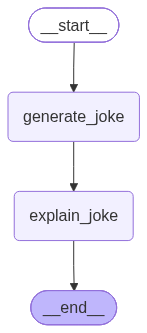

In [9]:
workflow

In [17]:
config1={"configurable":{"thread_id":"1"}}
workflow.invoke({"topic":"pizza"},config=config1)

{'topic': 'pizza',
 'joke': AIMessage(content='**Pizza‑Philosophy Joke**\n\n> **Why did the slice of pizza go to therapy?**  \n> Because it finally realized that being *topped* with expectations from everyone else was making it feel a little *crust‑fallen*—so it learned to embrace its own *cheesy* personality and let the sauce of life flow, one bite at a time.\n\n**The meaning:**  \nEven a perfect pizza can feel pressure when others keep piling on toppings (opinions, demands, comparisons). The joke reminds us to accept our own flavor, stay true to ourselves, and let the “sauce” of life add the spice—rather than letting external expectations make us feel crumbled. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want an expert joke writer. Provide a joke that has meaning (maybe a moral or commentary). Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_tokens': 199, 'prompt_tok

In [18]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Pizza‑Philosophy Joke**\n\n> **Why did the slice of pizza go to therapy?**  \n> Because it finally realized that being *topped* with expectations from everyone else was making it feel a little *crust‑fallen*—so it learned to embrace its own *cheesy* personality and let the sauce of life flow, one bite at a time.\n\n**The meaning:**  \nEven a perfect pizza can feel pressure when others keep piling on toppings (opinions, demands, comparisons). The joke reminds us to accept our own flavor, stay true to ourselves, and let the “sauce” of life add the spice—rather than letting external expectations make us feel crumbled. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want an expert joke writer. Provide a joke that has meaning (maybe a moral or commentary). Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_token

In [20]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Pizza‑Philosophy Joke**\n\n> **Why did the slice of pizza go to therapy?**  \n> Because it finally realized that being *topped* with expectations from everyone else was making it feel a little *crust‑fallen*—so it learned to embrace its own *cheesy* personality and let the sauce of life flow, one bite at a time.\n\n**The meaning:**  \nEven a perfect pizza can feel pressure when others keep piling on toppings (opinions, demands, comparisons). The joke reminds us to accept our own flavor, stay true to ourselves, and let the “sauce” of life add the spice—rather than letting external expectations make us feel crumbled. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want an expert joke writer. Provide a joke that has meaning (maybe a moral or commentary). Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_toke

In [21]:
config2={"configurable":{"thread_id":"2"}}
workflow.invoke({"topic":"pasta"},config=config2)

{'topic': 'pasta',
 'joke': AIMessage(content='**The Pasta Paradox**\n\nWhy did the spaghetti go to therapy?\n\nBecause it was tired of being *twisted* into everyone’s expectations—always “al dente,” always “perfectly seasoned,” always the side dish that never gets to be the main course. It finally realized that, like any good pasta, it doesn’t have to be boiled to perfection; it just needs the right sauce of self‑acceptance to taste amazing.\n\n*Lesson:* Even a humble noodle can find its flavor when it stops trying to fit the recipe and starts cooking its own story. 🍝😄', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want an expert joke writer. Provide a joke with meaning. Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 102, 'total_tokens': 268, 'completion_time': 0.348915705, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time'

In [22]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content='**The Pasta Paradox**\n\nWhy did the spaghetti go to therapy?\n\nBecause it was tired of being *twisted* into everyone’s expectations—always “al dente,” always “perfectly seasoned,” always the side dish that never gets to be the main course. It finally realized that, like any good pasta, it doesn’t have to be boiled to perfection; it just needs the right sauce of self‑acceptance to taste amazing.\n\n*Lesson:* Even a humble noodle can find its flavor when it stops trying to fit the recipe and starts cooking its own story. 🍝😄', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want an expert joke writer. Provide a joke with meaning. Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 102, 'total_tokens': 268, 'completion_time': 0.348915705, 'completion_tokens_details': {'reasoning_tokens'

In [24]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Pizza‑Philosophy Joke**\n\n> **Why did the slice of pizza go to therapy?**  \n> Because it finally realized that being *topped* with expectations from everyone else was making it feel a little *crust‑fallen*—so it learned to embrace its own *cheesy* personality and let the sauce of life flow, one bite at a time.\n\n**The meaning:**  \nEven a perfect pizza can feel pressure when others keep piling on toppings (opinions, demands, comparisons). The joke reminds us to accept our own flavor, stay true to ourselves, and let the “sauce” of life add the spice—rather than letting external expectations make us feel crumbled. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want an expert joke writer. Provide a joke that has meaning (maybe a moral or commentary). Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_toke

In [ ]:
list(workflow.get_state_history(config2)) ### data store in the RAM 

[StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content='**The Pasta Paradox**\n\nWhy did the spaghetti go to therapy?\n\nBecause it was tired of being *twisted* into everyone’s expectations—always “al dente,” always “perfectly seasoned,” always the side dish that never gets to be the main course. It finally realized that, like any good pasta, it doesn’t have to be boiled to perfection; it just needs the right sauce of self‑acceptance to taste amazing.\n\n*Lesson:* Even a humble noodle can find its flavor when it stops trying to fit the recipe and starts cooking its own story. 🍝😄', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want an expert joke writer. Provide a joke with meaning. Should be appropriate. No policy issues. Provide a joke.'}, response_metadata={'token_usage': {'completion_tokens': 166, 'prompt_tokens': 102, 'total_tokens': 268, 'completion_time': 0.348915705, 'completion_tokens_details': {'reasoning_tokens